# Medical Insurance Charges — Exploratory Data Analysis

This notebook is a cleaned and updated version of the analysis shown in the provided image. It uses current Seaborn syntax and keeps the original analysis topics: region, sex, smoker status, children, age, BMI, and categorical distributions.


## 1. Import libraries and prepare the DataFrame

The analysis expects a DataFrame named `df`. If `df` is not already loaded, the cell tries to read `insurance.csv` from the current Jupyter working directory.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# If df is already loaded, this will keep it.
# Otherwise, make sure insurance.csv is in the notebook folder.
try:
    df
except NameError:
    df = pd.read_csv('insurance.csv')

# The original image sometimes uses 'dr'. Keep this alias for compatibility.
dr = df.copy()

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Check the data

In [2]:
print(df.shape)
display(df.head())
display(df.info())
display(df.describe(include='all'))

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


None

,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


## 3. Region-wise charges by sex

This compares insurance charges across regions while separating the observations by sex.

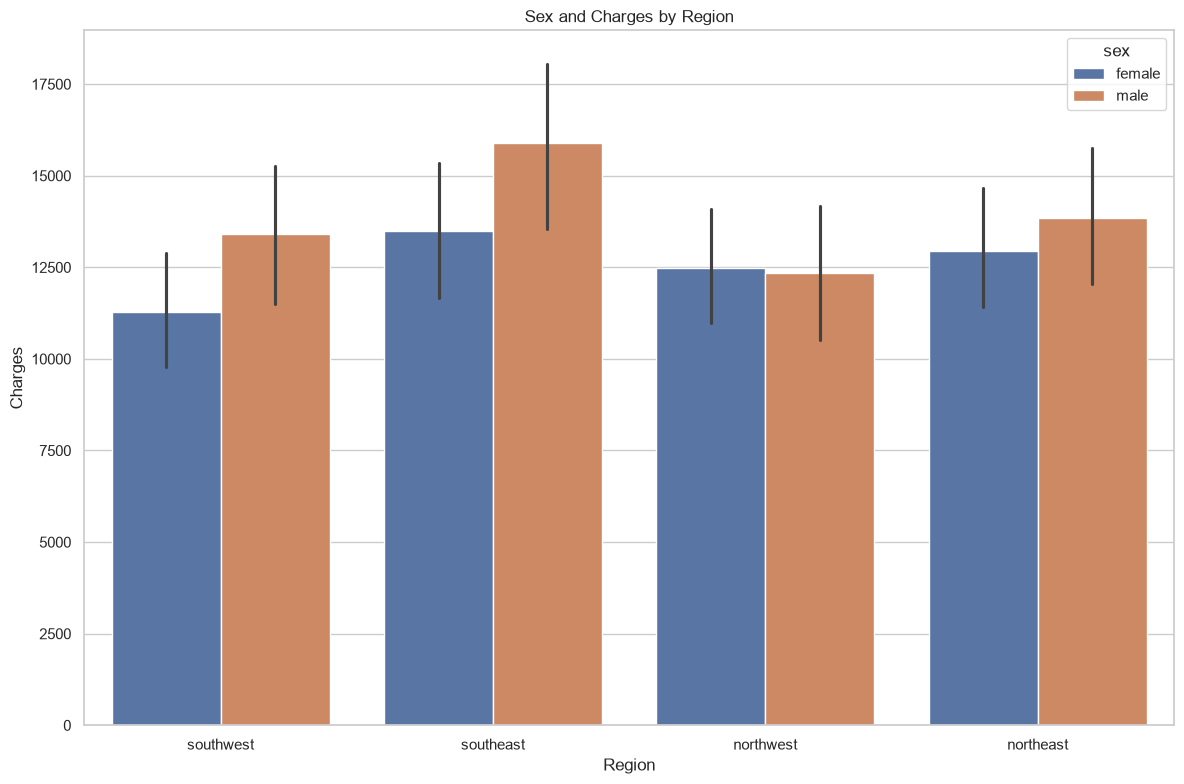

In [3]:
plt.figure(figsize=(12, 8))
sns.barplot(data=df, x='region', y='charges', hue='sex')
plt.title('Sex and Charges by Region')
plt.xlabel('Region')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

## 4. Region-wise charges by smoking status

This examines how smoker status relates to charges within each region.

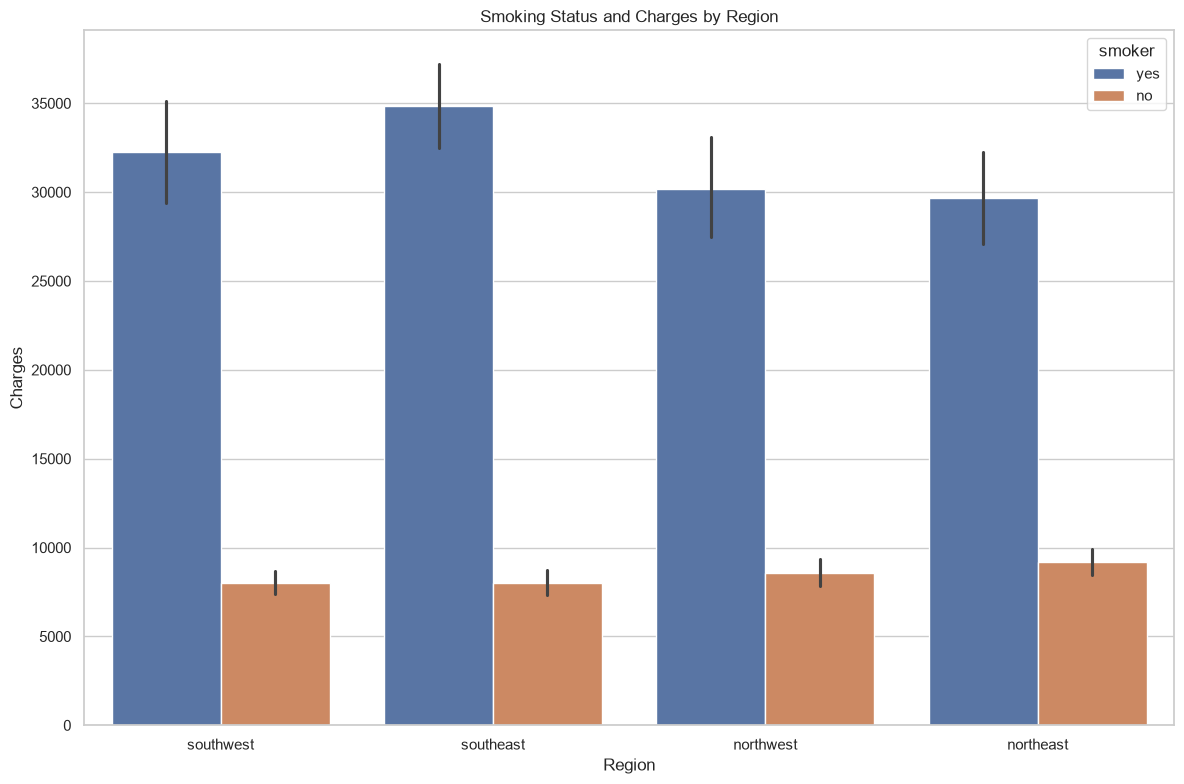

In [4]:
plt.figure(figsize=(12, 8))
sns.barplot(data=df, x='region', y='charges', hue='smoker')
plt.title('Smoking Status and Charges by Region')
plt.xlabel('Region')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

## 5. Region-wise charges by number of children

The `children` column is used as the grouping variable.

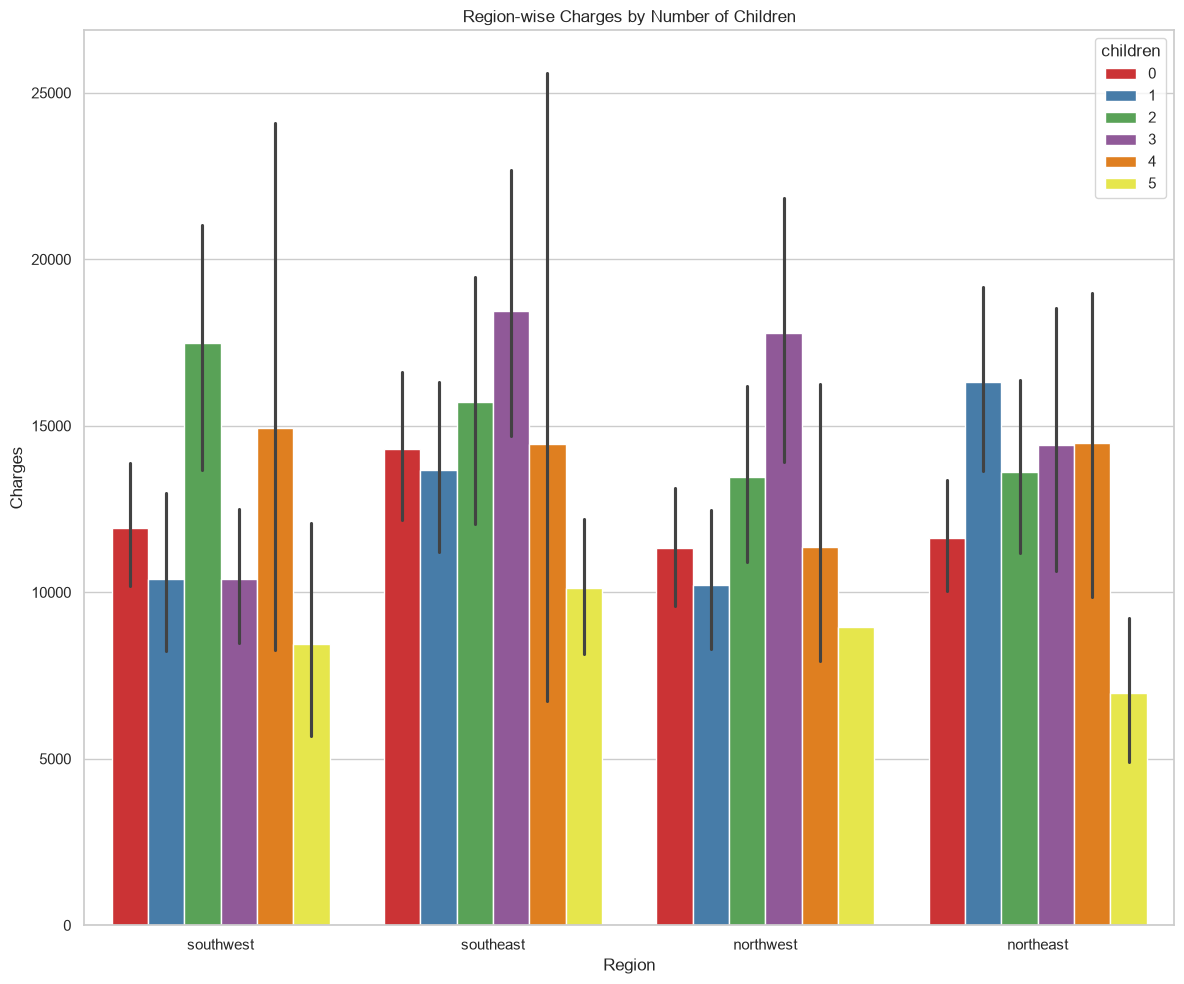

In [5]:
plt.figure(figsize=(12, 10))
sns.barplot(data=df, x='region', y='charges', hue='children', palette='Set1')
plt.title('Region-wise Charges by Number of Children')
plt.xlabel('Region')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

## 6. Age vs Charges

This plot shows how medical insurance charges vary with age.

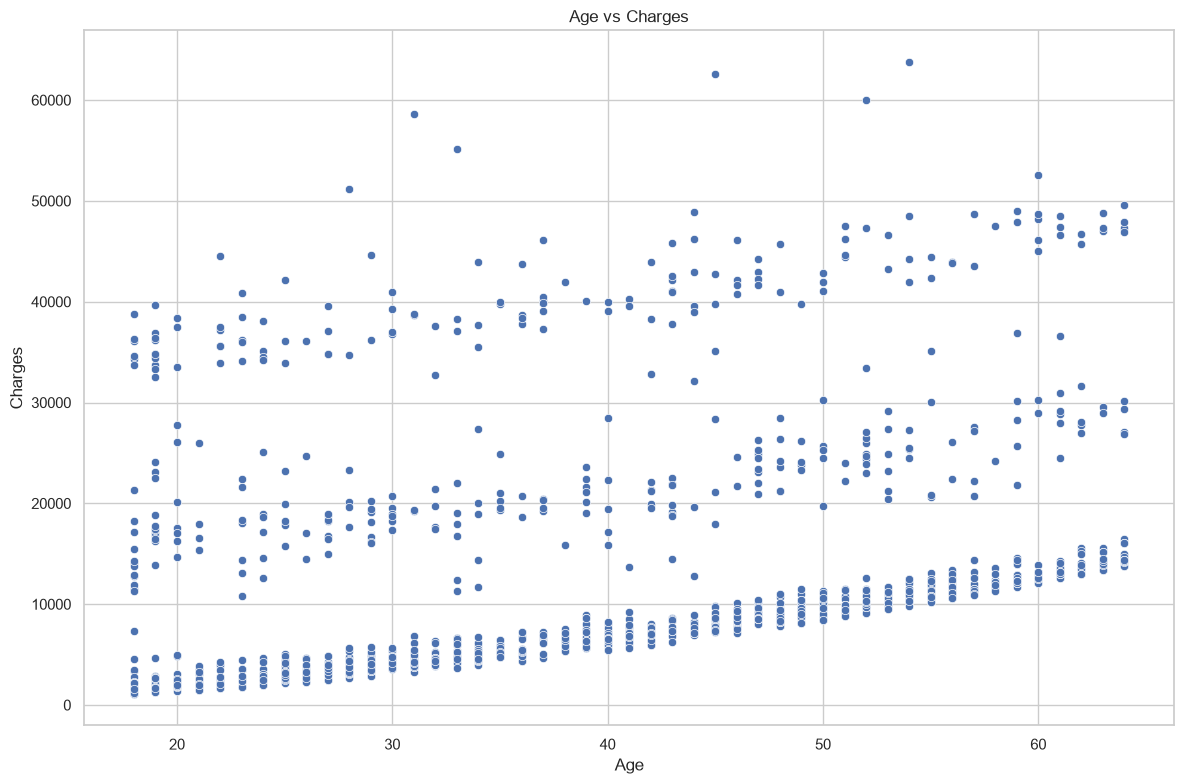

In [6]:
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df, x='age', y='charges')
plt.title('Age vs Charges')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

## 7. Sex vs Charges

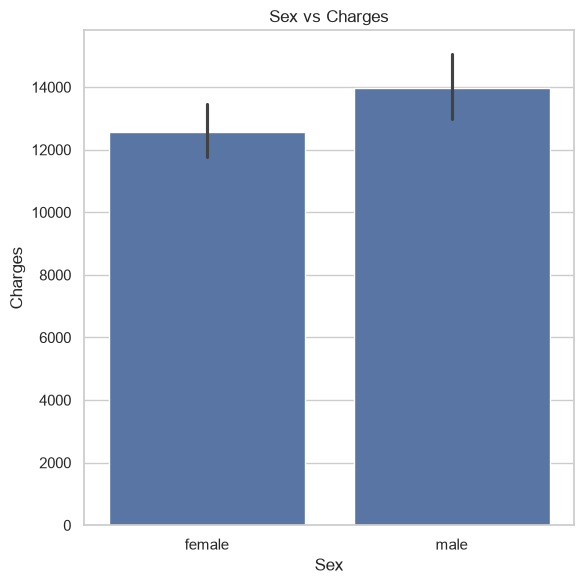

In [7]:
plt.figure(figsize=(6, 6))
sns.barplot(data=df, x='sex', y='charges')
plt.title('Sex vs Charges')
plt.xlabel('Sex')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

## 8. Smoker vs Charges

This compares the average insurance charge for smokers and non-smokers.

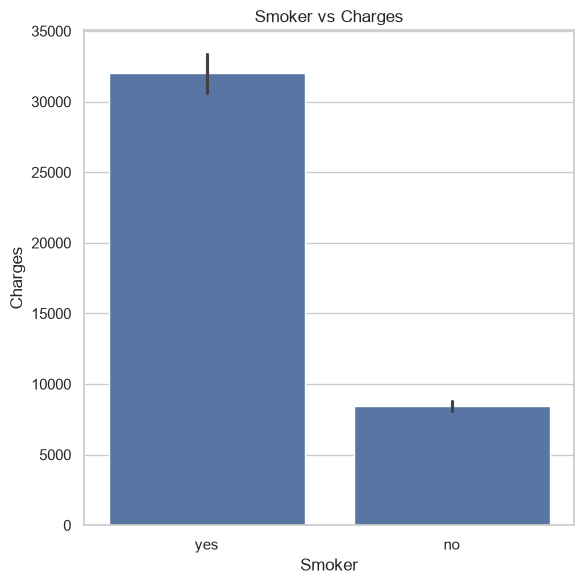

In [8]:
plt.figure(figsize=(6, 6))
sns.barplot(data=df, x='smoker', y='charges')
plt.title('Smoker vs Charges')
plt.xlabel('Smoker')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

## 9. BMI vs Charges

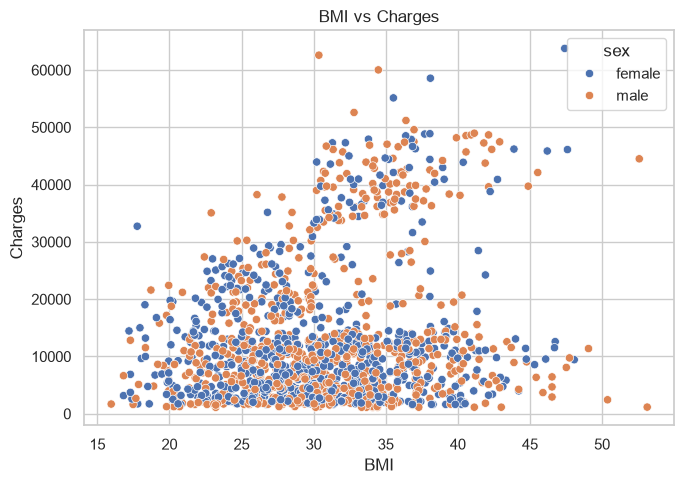

In [9]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='bmi', y='charges', hue='sex')
plt.title('BMI vs Charges')
plt.xlabel('BMI')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

## 10. Distribution of smoker, sex, region and children

The following 2×2 figure reproduces the distribution analysis from the image in a cleaner form.

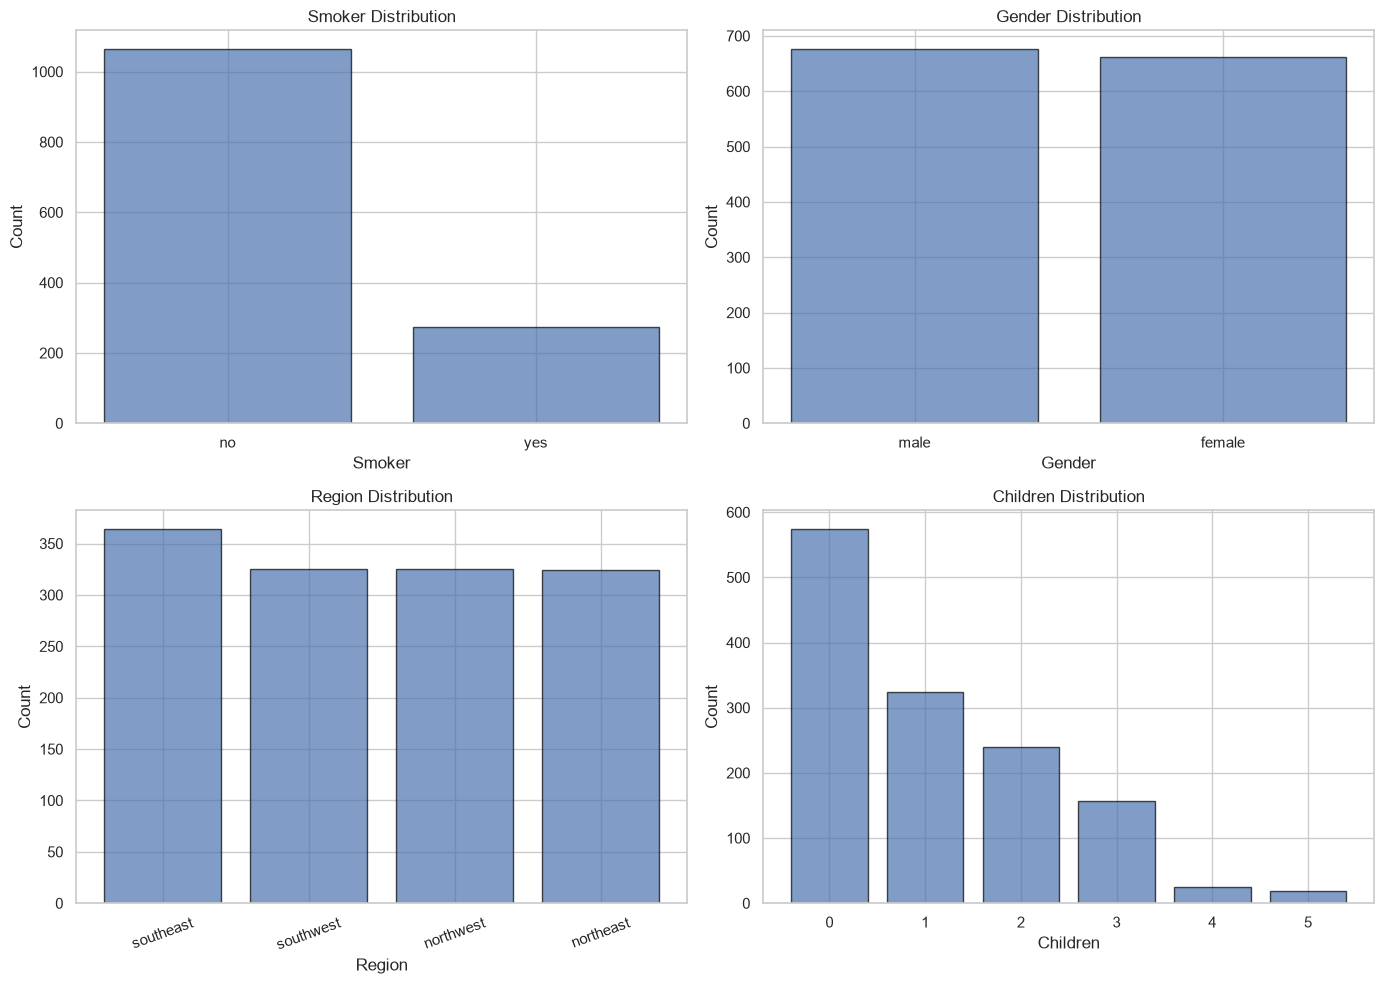

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Smoker distribution
smoker_counts = df['smoker'].value_counts()
axes[0, 0].bar(smoker_counts.index, smoker_counts.values,
                align='center', edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Smoker')
axes[0, 0].set_ylabel('Count')
axes[0, 0].set_title('Smoker Distribution')

# Sex distribution
sex_counts = df['sex'].value_counts()
axes[0, 1].bar(sex_counts.index, sex_counts.values,
                align='center', edgecolor='black', alpha=0.7)
axes[0, 1].set_xlabel('Gender')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title('Gender Distribution')

# Region distribution
region_counts = df['region'].value_counts()
axes[1, 0].bar(region_counts.index, region_counts.values,
                align='center', edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Region')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('Region Distribution')
axes[1, 0].tick_params(axis='x', rotation=20)

# Children distribution
children_counts = df['children'].value_counts().sort_index()
axes[1, 1].bar(children_counts.index.astype(str), children_counts.values,
                align='center', edgecolor='black', alpha=0.7)
axes[1, 1].set_xlabel('Children')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_title('Children Distribution')

plt.tight_layout()
plt.show()

## 11. Summary of average charges by region

The Seaborn bar plots above show the **mean** charge by default, not the total charge. This table makes that calculation explicit.

In [11]:
region_summary = (
    df.groupby('region')['charges']
      .agg(['mean', 'sum', 'count'])
      .sort_values('mean', ascending=False)
)

display(region_summary)

,mean,sum,count
region,,,
southeast,14735.411438,5.363690e+06,364
northeast,13406.384516,4.343669e+06,324
northwest,12417.575374,4.035712e+06,325
southwest,12346.937377,4.012755e+06,325


## Note

The original image uses older positional Seaborn syntax such as `sns.barplot(x, y, data=df)`. The notebook uses the current explicit form, for example `sns.barplot(data=df, x='sex', y='charges')`, which avoids the errors/warnings that can occur with newer Seaborn versions.